Now we move from song-level performance to artist-level performance

The main goal is to understand:

Which patterns characterize artists with repeated global chart presence?

We will deliberately avoid creating a single "best artist" ranking. Instead, we will analyze separate dimensions such as chart presence, productivity, longevity, streaming volume, Top-10 reach, consistency and repeat-hit behaviour.

### Artist Analytics

### Objectives

This notebook aggregates song-level Spotify Global Chart performance to the artist level.

The analysis examines:

- Artist chart presence
- Number of charting songs
- Total and median streams
- Chart longevity
- Top-10 performance
- Peak chart posiitons
- Repeat-hit behavior
- Artist consistency
- Artist concentration
- Relationship between artist productivity and performance

### Key Questions

1. Which artists have the largest number of charting songs?
2. How does artist productivity relate to total chart presence?
3. Which artists have repeated Top-10 appearances?
4. How does average performance differ from median performance?
5. Which artists demonstrate consistent chart longevity?
6. How concentrated is global chart activity among artists?
7. Do artists with many charting songs also have stronger aggregate performance?
8. What different artist performance profiles exist?

### Important Analytical Note

Artist-level statistics are descriptive aggregates of the song-level data.

Aggregate stream totals should not automatically be interpreted as artist quality or causal measures because they are strongly affected by the number of songs an artist has in the dataset.



In [2]:
# Import Libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
# Project Paths

PROJECT_ROOT = Path(
    r"C:\Users\Sanu\OneDrive\Desktop\Spotify-Global-Hit-Intelligence"
)

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "spotify_global_chart_totals_lyrics_cleaned.csv"
)

OUTPUT_DIR = (
    PROJECT_ROOT
    / "outputs"
    / "figures"
    / "artist_analytics"
)

TABLE_DIR = (
    PROJECT_ROOT
    / "outputs"
    / "tables"
    / "artist_analytics"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True 
)

TABLE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


print("Dataset exists:", DATA_PATH.exists())
print("Figure directory:", OUTPUT_DIR)
print("Table directory:", TABLE_DIR)

Dataset exists: True
Figure directory: C:\Users\Sanu\OneDrive\Desktop\Spotify-Global-Hit-Intelligence\outputs\figures\artist_analytics
Table directory: C:\Users\Sanu\OneDrive\Desktop\Spotify-Global-Hit-Intelligence\outputs\tables\artist_analytics


In [4]:
# Load the processed dataset

df= pd.read_csv(
    DATA_PATH,
    low_memory=False
)

print("Dataset shape:", df.shape)

Dataset shape: (8058, 29)


In [5]:
display(df.head())

,artist and title,wks,t10,pk,PkStreams,total,artist name,song name,lyrics,peak_duration,artist_song_key,artist_song_key_normalized,wks_outlier,t10_outlier,PkStreams_outlier,total_outlier,extreme_performance_count,log_total,log_wks,log_PkStreams,log_t10,lyrics_original,lyrics_available,lyrics_clean,lyrics_char_count,lyrics_word_count,lyrics_line_count,words_per_line,top10_reached
0,The Weeknd - Blinding Lights,347,64,1,52375259,5441240333,The Weeknd,Blinding Lights,Yeah I've been tryna call I've been on my own ...,13.0,The Weeknd | Blinding Lights,the weeknd | blinding lights,True,True,True,True,4,22.417273,5.852202,17.773945,4.174387,Yeah I've been tryna call I've been on my own ...,True,Yeah I've been tryna call I've been on my own ...,1230,259,1,259.0,1
1,Ed Sheeran - Shape of You,424,34,1,64217796,4470842634,Ed Sheeran,Shape of You,The club isn't the best place to find a lover ...,14.0,Ed Sheeran | Shape of You,ed sheeran | shape of you,True,True,True,True,4,22.220843,6.052089,17.977791,3.555348,The club isn't the best place to find a lover ...,True,The club isn't the best place to find a lover ...,3139,688,1,688.0,1
2,Harry Styles - As It Was,218,60,1,78460903,4417264164,Harry Styles,As It Was,﻿ As It Was - Harry Styles Come on Harry we wa...,11.0,Harry Styles | As It Was,harry styles | as it was,True,True,True,True,4,22.208786,5.389072,18.178111,4.110874,﻿ As It Was - Harry Styles Come on Harry we wa...,True,﻿ As It Was - Harry Styles Come on Harry we wa...,1143,243,1,243.0,1
3,The Neighbourhood - Sweater Weather,333,0,16,21624450,4142643719,The Neighbourhood,Sweater Weather,And all I am is a man I want the world in my h...,NaN,The Neighbourhood | Sweater Weather,the neighbourhood | sweater weather,True,False,False,True,2,22.144600,5.811141,16.889335,NaN,And all I am is a man I want the world in my h...,True,And all I am is a man I want the world in my h...,1678,345,1,345.0,0
4,Lewis Capaldi - Someone You Loved,343,15,4,24962682,3933581891,Lewis Capaldi,Someone You Loved,I'm going under and this time I fear there's n...,NaN,Lewis Capaldi | Someone You Loved,lewis capaldi | someone you loved,True,False,False,True,2,22.092816,5.840642,17.032893,2.772589,I'm going under and this time I fear there's n...,True,I'm going under and this time I fear there's n...,1555,323,1,323.0,1


In [6]:
# 5. Basic artist-level counts
# Start with the simplest measure: number of charting songs per artist


# ARTIST SONG COUNTS

artist_song_counts = (
    df.groupby("artist name")
    .agg(
        charting_songs = ("song name", "nunique")
    )
    .sort_values(
        "charting_songs",
        ascending=False
    )
)

display(
    artist_song_counts.head(25)
)

,charting_songs
artist name,
Drake,246
Taylor Swift,215
Bad Bunny,120
Ariana Grande,95
Eminem,89
The Weeknd,88
Kanye West,85
Justin Bieber,80
BTS,80


This measures chart presence/productivity, not necessarily performance.

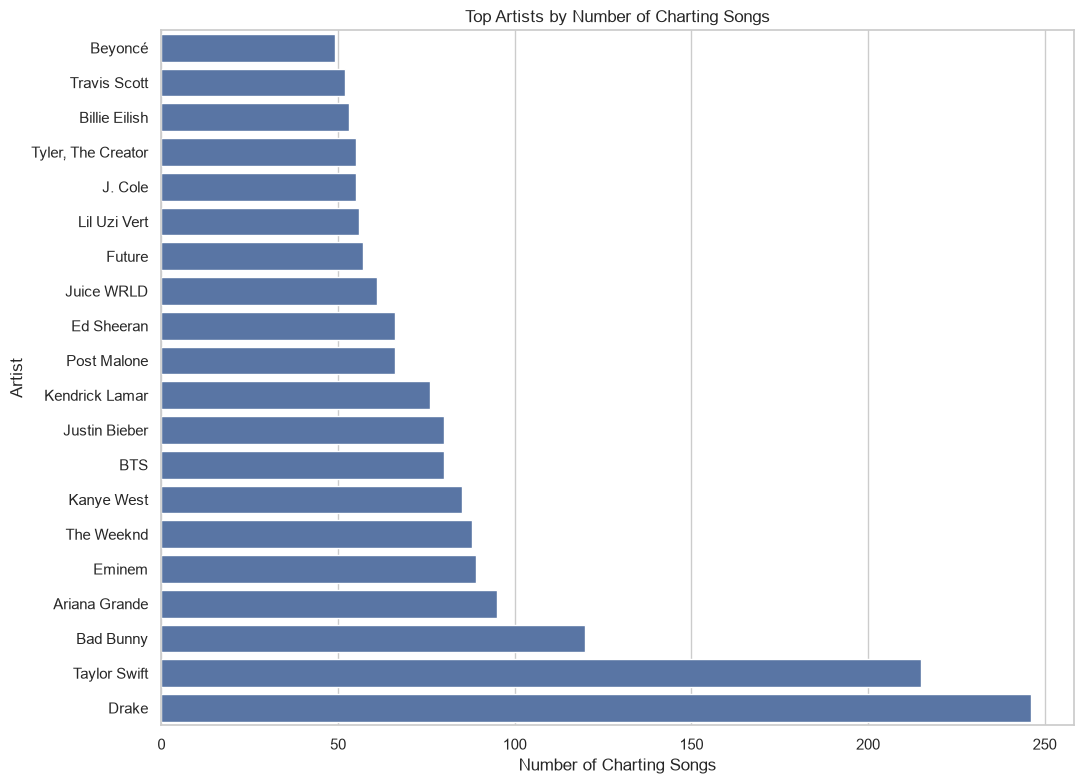

In [7]:
# 6. Visualize artist chart presence 

# TOP ARTISTS BY CHARTING SONGS

top_artist_counts = (
    artist_song_counts
    .head(20)
    .sort_values("charting_songs")
) 

plt.figure(figsize=(11, 8))


sns.barplot(
    data=top_artist_counts.reset_index(),
    x="charting_songs",
    y="artist name"
)

plt.title(
    "Top Artists by Number of Charting Songs"
)

plt.xlabel("Number of Charting Songs")
plt.ylabel("Artist")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "top_artists_by_charting_songs.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

In [8]:
# 7. Artist-level performance aggregation - Now build the main artist analytics table.

# ARTIST PERFORMANCE AGGREGATION

artist_performance = (
    df.groupby("artist name")
    .agg(
        charting_songs=("song name","nunique"),

        total_chart_streams=("total", "sum"),
        mean_total_streams=("total", "mean"),
        median_total_streams=("total", "median"),


        mean_weeks = ("wks", "mean"),
        median_weeks = ("wks", "median"),
        max_weeks = ("wks", "max"),

        mean_peak_position = ("pk", "mean"),
        median_peak_position = ("pk", "mean"),
        best_peak_position = ("pk", "min"),

        total_top10_weeks = ("t10", "sum"),
        mean_top19_weeks = ("t10", "mean"),

        top10_songs = ("top10_reached", "sum"),

        mean_peak_streams = ("PkStreams", "mean"),
        median_peak_streams = ("PkStreams", "median"),
        max_peak_streams = ("PkStreams", "max")

    )
)

artist_performance = (
    artist_performance
    .sort_values(
        "charting_songs",
        ascending=False
    )
)


display(
    artist_performance.head(20)
)

,charting_songs,total_chart_streams,mean_total_streams,median_total_streams,mean_weeks,median_weeks,max_weeks,mean_peak_position,median_peak_position,best_peak_position,total_top10_weeks,mean_top19_weeks,top10_songs,mean_peak_streams,median_peak_streams,max_peak_streams
artist name,,,,,,,,,,,,,,,,
Drake,246,22740546162,9.169575e+07,22343369.5,10.415323,3.0,325,49.411290,49.411290,1,196,0.790323,40,1.541683e+07,13006623.5,67499798
Taylor Swift,215,26273874386,1.157439e+08,31220010.0,8.224670,2.0,145,38.845815,38.845815,1,165,0.726872,53,2.459183e+07,18127237.0,128896137
Bad Bunny,120,31134387025,2.594532e+08,77444100.5,18.675000,7.0,105,36.450000,36.450000,1,247,2.058333,32,2.183460e+07,20000304.0,88786254
Ariana Grande,95,15600211489,1.625022e+08,33789754.5,15.562500,3.5,143,46.947917,46.947917,1,174,1.812500,26,1.792789e+07,13668040.0,71467874
Eminem,89,9322580059,1.047481e+08,13012310.0,14.303371,1.0,252,68.775281,68.775281,1,39,0.438202,7,1.133517e+07,9448084.0,56673473
The Weeknd,88,29875176511,3.048487e+08,28839470.0,28.010204,3.0,347,40.367347,40.367347,1,200,2.040816,24,1.604894e+07,14146249.0,54891152
Kanye West,85,3665343808,4.312169e+07,19738291.0,5.776471,2.0,48,67.411765,67.411765,1,13,0.152941,7,1.156466e+07,10900265.0,36147990
Justin Bieber,80,13990423095,1.706149e+08,26085045.5,16.341463,3.5,139,59.280488,59.280488,1,154,1.878049,17,1.504953e+07,10617901.5,66628394
BTS,80,7847627336,9.125148e+07,19289175.0,7.465116,2.0,113,62.906977,62.906977,1,61,0.709302,16,1.628045e+07,10280563.0,82268468


In [9]:
# 8. Calculate Top-10 rate 
# An artist with 20 songs and 10 Top-10 songs should be distinguished from an artist with 2 songs and both reaching the Top 10

# TOP-10 RATE

artist_performance["top10_rate"] = (
    artist_performance["top10_songs"]
    / artist_performance["charting_songs"]
)

artist_performance["top10_rate_pct"] = (
    artist_performance["top10_rate"] * 100
)


display(
    artist_performance[
        [
            "charting_songs",
            "top10_songs",
            "top10_rate_pct"
        ]
    ]
    .sort_values(
        "top10_rate_pct",
        ascending=False
    )
    .head(20)
)

,charting_songs,top10_songs,top10_rate_pct
artist name,,,
StaySolidRocky,1,2,200.0
The Police,1,1,100.0
Masked Wolf,1,1,100.0
Fourtwnty,1,1,100.0
Mike Posner,1,1,100.0
Saja Boys,2,2,100.0
Mitski,1,1,100.0
Aventura,1,1,100.0
Topic,1,1,100.0


Important

Do not interpret the artists at the top of this table as automatically having the strongest overall performance.

An artist with only one charting song can have a 100% Top-10 rate

In [10]:
# 9. Filter for artists with sufficient charting songs - For rate-based analysis, use a minimum  sample size

# ARTIST WITH AT LEAST 5 SONGS 

artists_5plus = artist_performance[
    artist_performance["charting_songs"] >= 5
].copy()

print(
    "Artists with at least 5 charting songs:",
    len(artists_5plus)
)

Artists with at least 5 charting songs: 316


In [11]:
# Now inspect Top-10 rate

display(
    artists_5plus[
        [
            "charting_songs",
            "top10_songs",
            "top10_rate_pct",
            "median_weeks",
            "median_total_streams"
        ]
    ]
    .sort_values(
        "top10_rate_pct",
        ascending=False
    )
    .head(20)
)

,charting_songs,top10_songs,top10_rate_pct,median_weeks,median_total_streams
artist name,,,,,
Luis Fonsi,5,3,60.000000,32.0,313526768.5
Dave,5,2,40.000000,10.0,83089567.0
Olivia Rodrigo,40,14,35.000000,6.0,86333347.5
Maroon 5,20,7,35.000000,20.0,55827120.0
Calvin Harris,29,10,34.482759,18.0,90180284.0
Clean Bandit,9,3,33.333333,32.0,280466909.0
Xavi,6,2,33.333333,15.0,160061176.0
PinkPantheress,6,2,33.333333,5.5,47323838.5
Iggy Azalea,6,2,33.333333,7.5,13398622.5


In [12]:
# 10. Artist aggregate streams - Calculate the artists  with the highest aggregate chart streams.abs

# TOTAL CHART STREAMS BY ARTIST 

top_artist_streams = (
    artist_performance
    .sort_values(
        "total_chart_streams",
        ascending=False
    )
    .head(20)
)

display(
    top_artist_streams[
        [
            "charting_songs",
            "total_chart_streams",
            "median_total_streams",
            "median_weeks"
        ]
    ]
)

,charting_songs,total_chart_streams,median_total_streams,median_weeks
artist name,,,,
Bad Bunny,120,31134387025,77444100.5,7.0
The Weeknd,88,29875176511,28839470.0,3.0
Taylor Swift,215,26273874386,31220010.0,2.0
Drake,246,22740546162,22343369.5,3.0
Billie Eilish,53,21972201869,122634392.0,12.0
Ed Sheeran,66,21777307945,40819170.0,7.0
Post Malone,66,19237721490,59593759.5,7.0
Ariana Grande,95,15600211489,33789754.5,3.5
Justin Bieber,80,13990423095,26085045.5,3.5


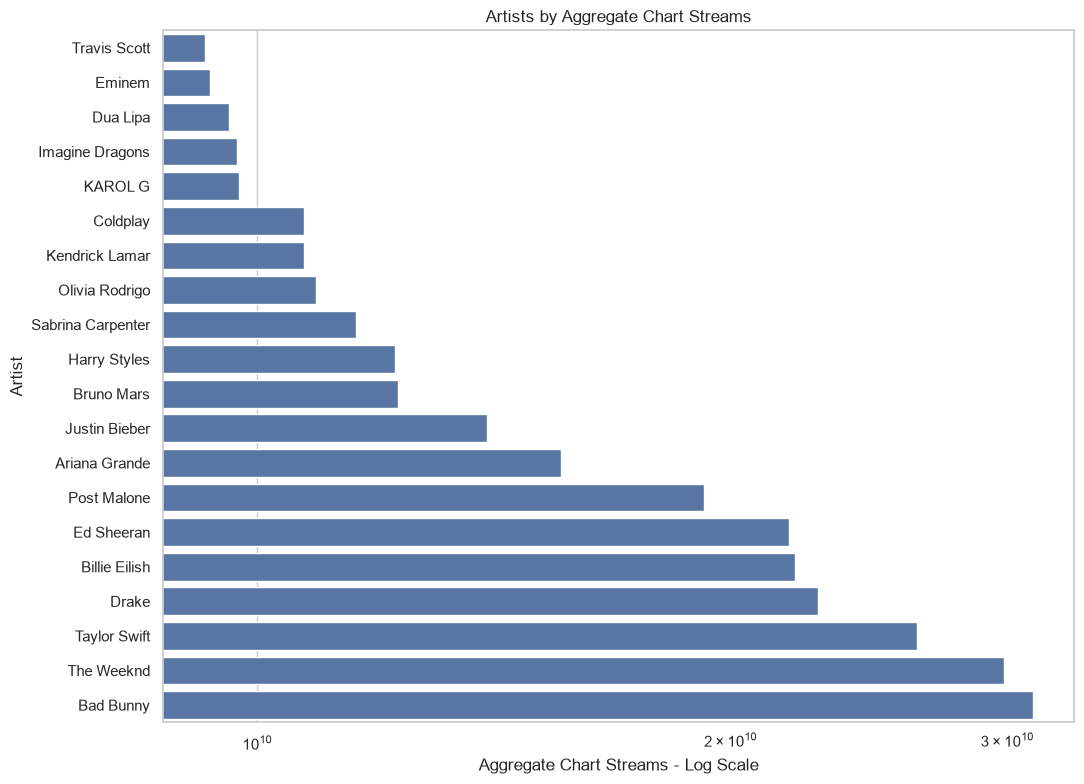

In [13]:
# 11. Visualize aggregate artist streams 

plot_data = (
    top_artist_streams[
        ["total_chart_streams"]
    ]
    .sort_values("total_chart_streams")
)

plt.figure(figsize=(11, 8))

sns.barplot(
    data=plot_data.reset_index(),
    x="total_chart_streams",
    y="artist name"
)

plt.xscale("log")

plt.title(
    "Artists by Aggregate Chart Streams"
)

plt.xlabel(
    "Aggregate Chart Streams - Log Scale"
)

plt.ylabel("Artist")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "artists_by_aggregate_streams.png",
    dpi=300,
    bbox_inches = "tight"
)

plt.show()
plt.close()

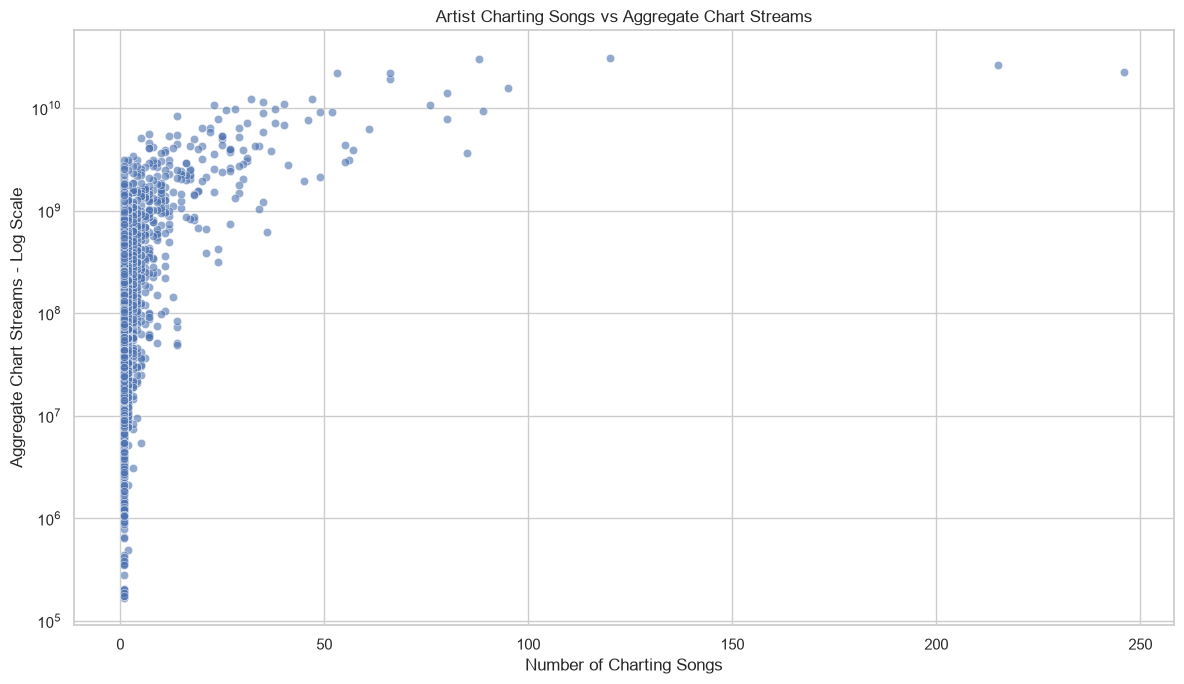

In [14]:
# 12. Aggregate streams vs number of songs
# This is an important analysis because aggregate streams are naturally influenced by the number of songs


# ARTIST PRODUCTIVITY VS AGGREGATE STREAMS

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=artist_performance,
    x="charting_songs",
    y="total_chart_streams",
    alpha=0.6
)

plt.yscale("log")

plt.title(
    "Artist Charting Songs vs Aggregate Chart Streams"
)

plt.xlabel("Number of Charting Songs")
plt.ylabel("Aggregate Chart Streams - Log Scale")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "artist_productivity_vs_streams.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

In [15]:
# Calculate the correlation

productivity_stream_corr = (
    artist_performance[
        [
            "charting_songs",
            "total_chart_streams"
        ]
    ]
    .corr()
    .iloc[0, 1]
)

print(
    f"Correlation: {productivity_stream_corr:.3f}"
)

Correlation: 0.824


This helps distinguish:

More charting songs 
|
more oppurtunities to accumulate aggregate streams

from the separate question of:

How strong is the typical song?

In [16]:
# 13. Median performance by artist

# Median performance is useful because a single blockbuster can heavily influence an artist's mean.abs

# MEDIAN SONG PERFORMANCE

median_artist_performance = (
    artist_performance[
        artist_performance["charting_songs"] >= 5
    ]
    .sort_values(
        "median_total_streams",
        ascending=False
    )
)

display(
    median_artist_performance[
        [
            "charting_songs",
            "median_total_streams",
            "median_weeks",
            "median_peak_position",
            "median_peak_streams"
        ]
    ]
    .head(20)
)

,charting_songs,median_total_streams,median_weeks,median_peak_position,median_peak_streams
artist name,,,,,
Jonas Blue,7,430111732.0,45.0,50.000000,16501675.0
MEDUZA,5,379486906.0,43.0,89.000000,13041541.0
The Neighbourhood,5,370875846.0,46.0,89.400000,8991355.0
sombr,7,346775920.0,24.0,60.000000,19085640.0
Luis Fonsi,5,313526768.5,32.0,57.666667,13761298.5
Clean Bandit,9,280466909.0,32.0,50.777778,8491112.0
Charlie Puth,10,255482632.0,37.5,44.200000,11799151.5
Benson Boone,7,250941954.0,31.0,55.285714,12626142.0
Nio Garcia,5,238320413.5,21.5,24.833333,18206698.0


This is a better way to study typical song performance within an artist's charting catalog.

In [17]:
# 14. Mean vs median performance

# Let's explicity investigate the difference

# MEAN VS MEDIAN 

mean_median_comparison = (
    artist_performance[
        artist_performance["charting_songs"] >= 5
    ]
    [
        [
            "charting_songs",
            "mean_total_streams",
            "median_total_streams"
        ]
    ]
    .copy()
)

mean_median_comparison["mean_median_ratio"] = (
    mean_median_comparison["mean_total_streams"]
    /
    mean_median_comparison["median_total_streams"]
)

display(
    mean_median_comparison
    .sort_values(
        "mean_median_ratio",
        ascending=False
    )
    .head(20)
)

,charting_songs,mean_total_streams,median_total_streams,mean_median_ratio
artist name,,,,
Arctic Monkeys,14,6.014851e+08,6685482.5,89.968846
Hozier,7,5.882820e+08,22192237.0,26.508458
Tame Impala,8,1.752173e+08,7142364.0,24.532112
Mariah Carey,5,4.773894e+08,22024135.0,21.675741
Lil Nas X,22,2.485219e+08,13038116.5,19.061181
Meek Mill,19,3.551625e+07,2157053.0,16.465171
Gorillaz,7,1.469689e+08,9067357.0,16.208574
Frank Ocean,9,1.420821e+08,9231075.0,15.391712
Lady Gaga,49,1.822283e+08,12524773.5,14.549428


A high ratio suggests that an artist's average is being pulled upward by some unusually large-performing songs.

# 15. Artist consistency 

We can measure variation in song performance

Use the coefficient of variation:

CV = Standard Deviation / Mean



In [18]:
# ARTIST PERFORMANCE CONSISTENCY 

artist_consistency = (
    df.groupby("artist name")
    .agg(
        charting_songs=("song name", "nunique"),
        mean_total=("total", "mean"),
        std_total=("total", "std"),
        median_total=("total", "median")
    )
)

artist_consistency["cv_total_streams"] = (
    artist_consistency["std_total"]
    / artist_consistency["mean_total"]
)

artist_consistency = (
    artist_consistency[
        artist_consistency["charting_songs"] >= 5
    ]
    .sort_values(
        "cv_total_streams"
    )
)


display(
    artist_consistency.head(20)
)

,charting_songs,mean_total,std_total,median_total,cv_total_streams
artist name,,,,,
RIN,5,4.971995e+06,8.007992e+05,4947824.0,0.161062
Brent Faiyaz,5,6.308565e+06,1.137157e+06,5854629.0,0.180256
Sfera Ebbasta,9,5.672282e+06,1.759371e+06,5263469.0,0.310170
Loredana,7,8.411729e+06,3.050831e+06,9053276.0,0.362688
Ufo361,14,5.962766e+06,2.322529e+06,5086780.0,0.389505
KC Rebell,5,6.130992e+06,2.637881e+06,5029858.0,0.430254
Gusttavo Lima,5,4.433480e+07,1.985097e+07,47222860.0,0.447752
Ninho,5,7.190887e+06,3.237659e+06,5971496.0,0.450245
Sleep Token,6,1.322577e+07,6.397126e+06,9480303.0,0.483687


Lower CV indicates less relative variation among an artist's songs in this descriptive measure.

Don't interpret it as "better consistency"; it simply quantifies dispersion.

In [19]:
# 16. Artist longevity

# Let's analyze the typical chart duration of an artist's songs.abs


# ARTIST LONGEVITY

artist_longevity = (
    df.groupby("artist name")
    .agg(
        charting_songs=("song name", "nunique"),
        mean_weeks = ("wks", "mean"),
        median_weeks = ("wks", "median"),
        max_weeks = ("wks", "max")
    )
)

artist_longevity_5plus = (
    artist_longevity[
        artist_longevity["charting_songs"] >= 5
    ]
    .sort_values(
        "median_weeks",
        ascending=False
    )
)

display(
    artist_longevity_5plus.head(20)
)

,charting_songs,mean_weeks,median_weeks,max_weeks
artist name,,,,
The Neighbourhood,5,97.000000,46.0,333
Jonas Blue,7,36.857143,45.0,62
MEDUZA,5,32.600000,43.0,62
Charlie Puth,10,45.000000,37.5,136
DJ Snake,11,37.909091,35.0,135
Hailee Steinfeld,6,35.333333,34.0,66
Clean Bandit,9,41.000000,32.0,121
Luis Fonsi,5,33.333333,32.0,64
Benson Boone,7,39.142857,31.0,131


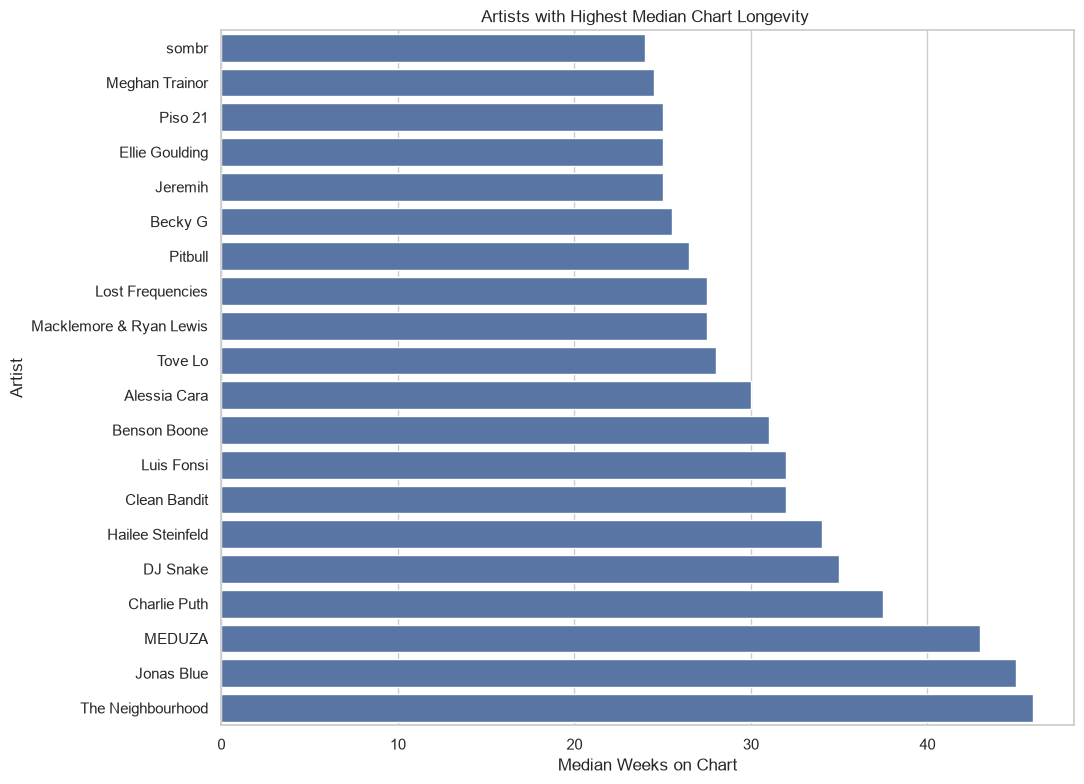

In [20]:
# 17. Visualize artist longevity

top_longevity_artists = (
    artist_longevity_5plus
    .head(20)
    .sort_values("median_weeks")
)

plt.figure(figsize=(11, 8))

sns.barplot(
    data=top_longevity_artists.reset_index(),
    x="median_weeks",
    y="artist name"
)

plt.title(
    "Artists with Highest Median Chart Longevity "
)


plt.xlabel("Median Weeks on Chart")
plt.ylabel("Artist")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "artist_median_chart_longevity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

In [21]:
# 18. Artist peak-position performance - Lower pk is better

# ARTIST PEAK POSITION

artist_peak = (
    df.groupby("artist name")
    .agg(
        charting_songs=("song name", "nunique"),
        median_peak_position=("pk", "median"),
        best_peak_position=("pk", "min"),
        top10_songs=("top10_reached", "sum")

    )
)

artist_peak_5plus = (
    artist_peak[
        artist_peak["charting_songs"] >= 5
    ]
    .sort_values(
        "median_peak_position"
    )
)

display(
    artist_peak_5plus.head(20)
)

,charting_songs,median_peak_position,best_peak_position,top10_songs
artist name,,,,
Jonas Blue,7,12.0,10,1
LISA,7,13.0,5,2
Olivia Rodrigo,40,13.0,1,14
Nio Garcia,5,13.5,8,1
Charlie Puth,10,18.0,5,3
Billie Eilish,53,20.0,1,16
sombr,7,21.0,1,2
Tainy,6,21.5,12,0
DJ Snake,11,22.0,1,3


In [22]:
# 19. Repeat Top-10 artists - Now investigate repeated Top-10 presence

# REPEAT TOP-10 PERFORMANCE 

repeat_top10_artists = (
    artist_performance[
        artist_performance["top10_songs"] >= 2
    ]
    .sort_values(
        [
            "top10_songs",
            "total_top10_weeks"
        ],
        ascending=False
    )
)

display(
    repeat_top10_artists[
        [
            "charting_songs",
            "top10_songs",
            "total_top10_weeks",
            "top10_rate_pct",
            "median_weeks",
            "median_total_streams"
        ]
    ].head(25)
)

,charting_songs,top10_songs,total_top10_weeks,top10_rate_pct,median_weeks,median_total_streams
artist name,,,,,,
Taylor Swift,215,53,165,24.651163,2.0,31220010.0
Drake,246,40,196,16.260163,3.0,22343369.5
Bad Bunny,120,32,247,26.666667,7.0,77444100.5
Ariana Grande,95,26,174,27.368421,3.5,33789754.5
The Weeknd,88,24,200,27.272727,3.0,28839470.0
Post Malone,66,18,147,27.272727,7.0,59593759.5
Justin Bieber,80,17,154,21.250000,3.5,26085045.5
Ed Sheeran,66,16,179,24.242424,7.0,40819170.0
Billie Eilish,53,16,138,30.188679,12.0,122634392.0


This measures repeat Top-10 presence, rather than simply whether an artist ever had one Top-10 song.

In [23]:
# 20. Artists with repeated long-running songs
# Define a long-running song using the 75th percentile of wks

# REPEATED LONG-RUNNING SONGS


longevity_threshold = df["wks"].quantile(0.75)

print(
    f"75th percentile chart longevity: "
    f"{longevity_threshold:.2f} weeks"
)

df["long_running_song"] = (
    df["wks"] >= longevity_threshold
)

75th percentile chart longevity: 17.00 weeks


In [24]:
# Count by artist

artist_long_running = (
    df.groupby("artist name")
    .agg(
        charting_songs=("song name", "nunique"),
        long_running_songs = ("long_running_song", "sum")
    )
)

artist_long_running["long_running_rate"] = (
    artist_long_running["long_running_songs"] 
    / artist_long_running["charting_songs"]
    )

artist_long_running_5plus = (
    artist_long_running[
        artist_long_running["charting_songs"] >= 5
    ]
    .sort_values(
        "long_running_songs",
        ascending=False
    )

)

display(
    artist_long_running_5plus.head(25)
)


,charting_songs,long_running_songs,long_running_rate
artist name,,,
Bad Bunny,120,44,0.366667
Drake,246,43,0.174797
The Weeknd,88,29,0.329545
Taylor Swift,215,25,0.116279
Ed Sheeran,66,23,0.348485
Ariana Grande,95,23,0.242105
Billie Eilish,53,21,0.396226
J Balvin,40,21,0.525000
Justin Bieber,80,21,0.262500


In [25]:
# 21 . Artist performance profiles

# Rather than ranking artists into one overall score, classify them into descriptive profiles based on catalog size and median song streams.

# First calculate thresholds

eligible_artists = artist_performance[
    artist_performance["charting_songs"] >= 5
].copy()

song_count_threshold = (
        eligible_artists["charting_songs"]
        .median()
)

median_stream_threshold = (
    eligible_artists["median_total_streams"]
    .median()
)

print(
    "Median charting-song count:",
    song_count_threshold
)

print(
    "Median artist median streams:",
    f"{median_stream_threshold:,.0f}"
)


Median charting-song count: 10.0
Median artist median streams: 31,296,984


In [26]:
# Create profiles

eligible_artists["artist_profile"] = np.select(
    [
        (
            eligible_artists["charting_songs"]
            >= song_count_threshold
        )
        &
        (
            eligible_artists["median_total_streams"]
            >= median_stream_threshold
        ),

        (
            eligible_artists["charting_songs"]
            >= song_count_threshold
        )

        &

        (

            eligible_artists["median_total_streams"]
            < median_stream_threshold
        ),

        (
            eligible_artists["charting_songs"]
            < song_count_threshold
        )

        &

        (

            eligible_artists["median_total_streams"]
            >= median_stream_threshold
        )
    ],

    [
        "High Catalog Presence + High Typical Performance",
        "High Catalog Presence + Lower Typical Performance",
        "Lower Catalog Presence + High Typical Performance"
    ],
    default = "Lower Catalog Presence + Lower Typical Performance"
)

display(
    eligible_artists["artist_profile"]
    .value_counts()
)

artist_profile
High Catalog Presence + Lower Typical Performance     91
Lower Catalog Presence + High Typical Performance     83
High Catalog Presence + High Typical Performance      75
Lower Catalog Presence + Lower Typical Performance    67
Name: count, dtype: int64

In [27]:
# 22. Profile Summary

artist_profile_summary = (
    eligible_artists
    .groupby("artist_profile")
    .agg(
        artists=("charting_songs", "size"),
        median_catalog_size=("charting_songs", "median"),
        median_song_streams=("median_total_streams", "median"),
        median_weeks = ("median_weeks", "median"),
        median_top10_rate=("top10_rate", "median")
    )
)

artist_profile_summary["median_top10_rate"] *= 100

display(artist_profile_summary)

,artists,median_catalog_size,median_song_streams,median_weeks,median_top10_rate
artist_profile,,,,,
High Catalog Presence + High Typical Performance,75,17.0,74942507.0,13.0,15.789474
High Catalog Presence + Lower Typical Performance,91,22.0,13973712.0,2.0,5.882353
Lower Catalog Presence + High Typical Performance,83,6.0,84145207.5,13.5,0.000000
Lower Catalog Presence + Lower Typical Performance,67,6.0,13305785.0,2.0,0.000000


In [28]:
# 23. Artist concentration - Measure how much chart representation comes from the top artists

# ARTIST CONCENTRATION

artist_concentration = (
    artist_song_counts
    .reset_index()
    .rename(
        columns={
            "charting_songs": "song_count"
        }
    )
    .sort_values(
        "song_count",
        ascending=False
    )
)

artist_concentration["cumulative_songs"] = (
    artist_concentration["song_count"]
    .cumsum()
)

artist_concentration["cumulative_share"] = (
    artist_concentration["cumulative_songs"]
    / artist_concentration["song_count"].sum()
    * 100
)

display(
    artist_concentration.head(20)
)

,artist name,song_count,cumulative_songs,cumulative_share
0,Drake,246,246,3.144172
1,Taylor Swift,215,461,5.892127
2,Bad Bunny,120,581,7.425869
3,Ariana Grande,95,676,8.640082
4,Eminem,89,765,9.777607
5,The Weeknd,88,853,10.902352
6,Kanye West,85,938,11.988753
7,Justin Bieber,80,1018,13.011247
8,BTS,80,1098,14.033742
9,Kendrick Lamar,76,1174,15.005112


In [29]:
# Calculate top artist shares:

for n in [10, 25, 50, 100]:

    share = (
        artist_concentration
        .head(n)["song_count"]
        .sum()
        / len(df)
        * 100
    )

    print(
        f"Top {n} artists account for "
        f"{share:.2f}% of chart records."
    )

Top 10 artists account for 14.57% of chart records.
Top 25 artists account for 24.47% of chart records.
Top 50 artists account for 34.77% of chart records.
Top 100 artists account for 48.18% of chart records.


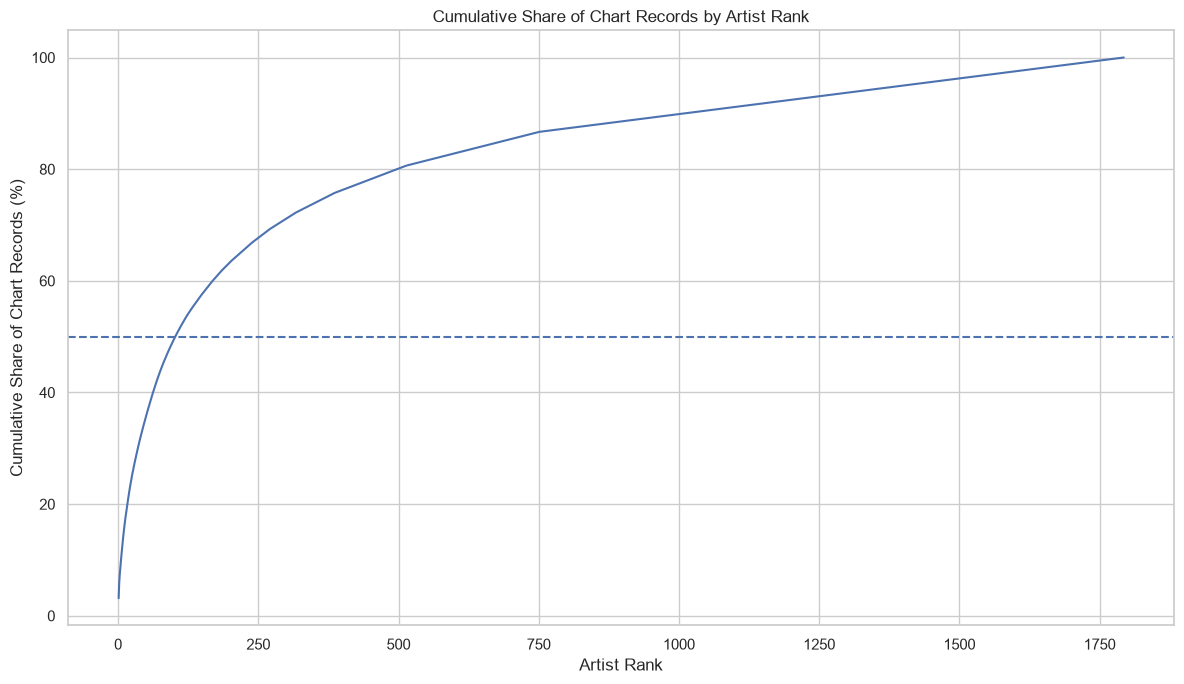

In [30]:
# 24. Artist concentration curve

plt.figure(figsize=(12, 7))

plt.plot(
    range(1, len(artist_concentration) + 1),
    artist_concentration["cumulative_share"]
)

plt.axhline(
    50,
    linestyle="--"
)

plt.title(
    "Cumulative Share of Chart Records by Artist Rank"
)

plt.xlabel("Artist Rank")
plt.ylabel("Cumulative Share of Chart Records (%)")


plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "artist_concentration_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

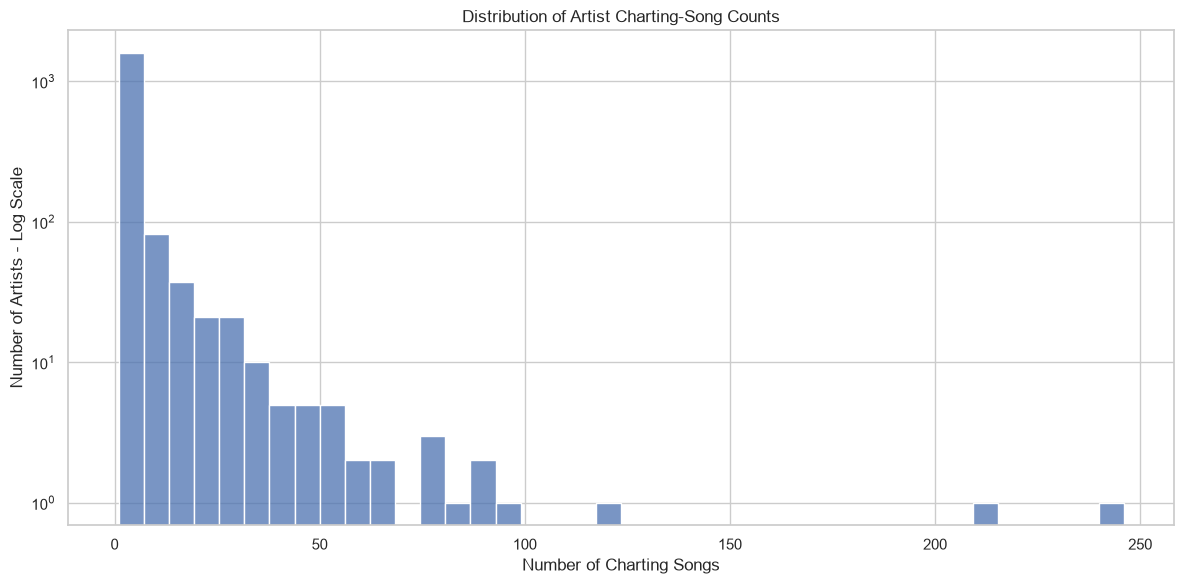

In [31]:
# 25. Artist catalog size distribution

# ARTIST CATALOG SIZE

plt.figure(figsize=(12, 6))

sns.histplot(
    artist_song_counts["charting_songs"],
    bins=40
)

plt.yscale("log")

plt.title(
    "Distribution of Artist Charting-Song Counts"
)

plt.xlabel("Number of Charting Songs")
plt.ylabel("Number of Artists - Log Scale")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "artist_catalog_size_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

In [32]:
# 26. Artist catalog size categories

def classify_catalog_size(count):

    if count == 1:
        return "1 song"

    elif count <= 3:
        return "2-3 songs"

    elif count <= 5:
        return "4-5 songs"

    elif count <= 10:
        return "6-10 songs"

    elif count <= 25:
        return "11-25 songs"

    else:
        return "26+ songs"

artist_concentration["catalog_size_group"] = (
    artist_concentration["song_count"]
    .apply(classify_catalog_size)
)

catalog_order= [
    "1 song",
    "2-3 songs",
    "4-5 songs",
    "6-10 songs",
    "11-25 songs",
    "26+ songs"
]

catalog_distribution = (
    artist_concentration["catalog_size_group"]
    .value_counts()
    .reindex(catalog_order)
)

display(catalog_distribution)

catalog_size_group
1 song         1043
2-3 songs       365
4-5 songs       115
6-10 songs      123
11-25 songs      87
26+ songs        60
Name: count, dtype: int64

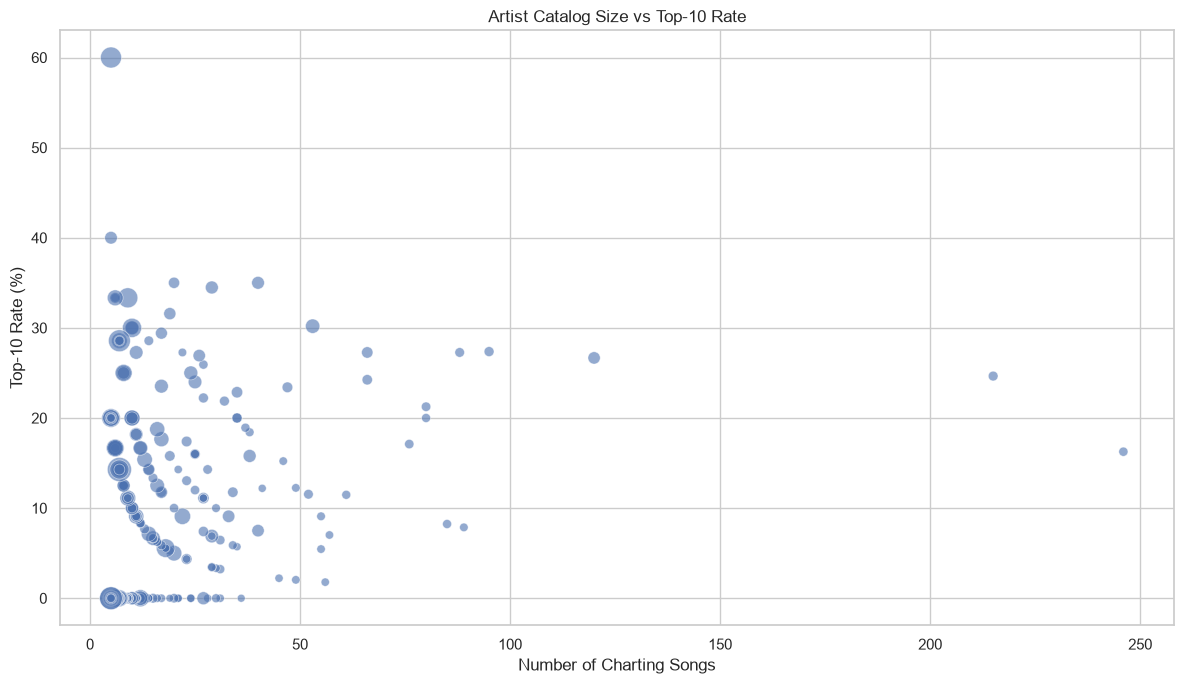

In [33]:
# 27. Artist-level relationship: catalog size vs Top-10 rate

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=eligible_artists,
    x="charting_songs",
    y="top10_rate_pct",
    size="median_total_streams",
    sizes=(30, 300),
    alpha=0.6,
    legend=False
)

plt.title(
    "Artist Catalog Size vs Top-10 Rate"
)

plt.xlabel("Number of Charting Songs")
plt.ylabel("Top-10 Rate (%)")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "artist_catalog_size_vs_top1_rate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

This is descriptive only. A relationship here should not be interpreted as a causal effect of catalog size.

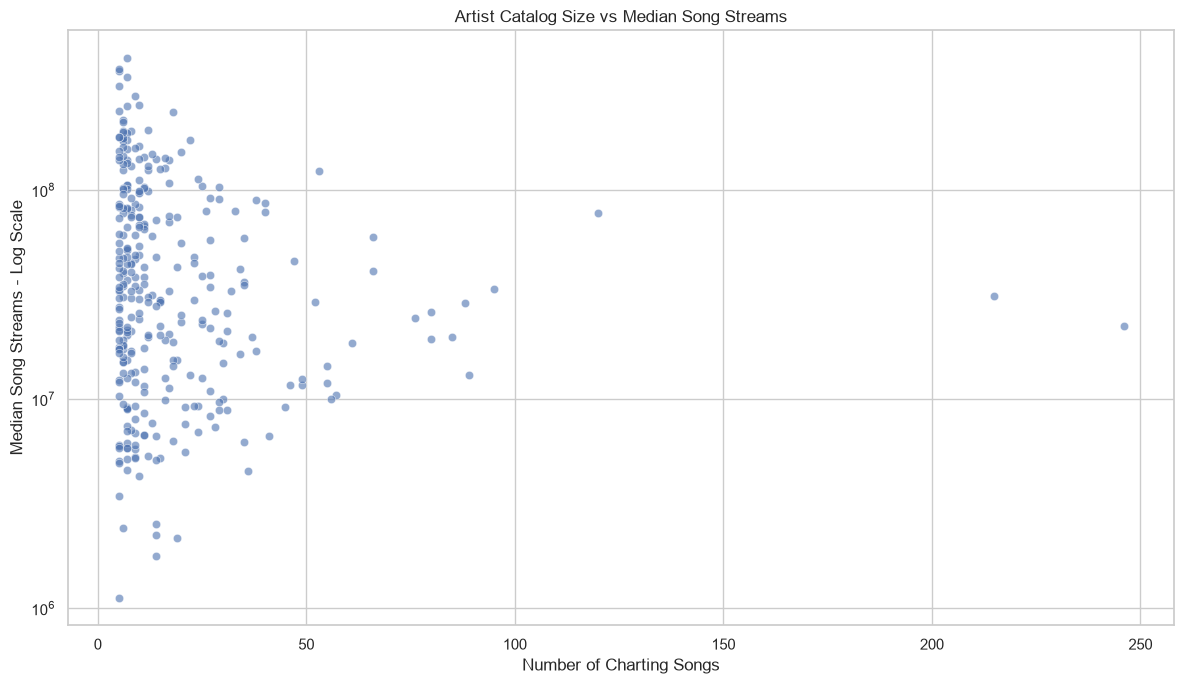

In [34]:
# 28. Artist catalog size vs median song performance 

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=eligible_artists,
    x="charting_songs",
    y="median_total_streams",
    alpha=0.6
)

plt.yscale("log")

plt.title(
    "Artist Catalog Size vs Median Song Streams"
)

plt.xlabel("Number of Charting Songs")
plt.ylabel("Median Song Streams - Log Scale")

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "artist_catalog_size_vs_media_streams.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

In [35]:
# 29. Calculate artist-level correlations

artist_corr_cols = [
    "charting_songs",
    "total_chart_streams",
    "median_total_streams",
    "median_weeks",
    "median_peak_position",
    "top10_rate",
    "median_peak_streams"
]

artist_correlations = (
    artist_performance[
        artist_corr_cols
    ]
    .corr()
)

display(artist_correlations)

,charting_songs,total_chart_streams,median_total_streams,median_weeks,median_peak_position,top10_rate,median_peak_streams
charting_songs,1.000000,0.823509,-0.068580,-0.082161,-0.128746,0.099248,0.059669
total_chart_streams,0.823509,1.000000,0.094385,0.077223,-0.226277,0.213540,0.189694
median_total_streams,-0.068580,0.094385,1.000000,0.891916,-0.446995,0.442277,0.613843
median_weeks,-0.082161,0.077223,0.891916,1.000000,-0.472400,0.326933,0.397229
median_peak_position,-0.128746,-0.226277,-0.446995,-0.472400,1.000000,-0.371278,-0.602742
top10_rate,0.099248,0.213540,0.442277,0.326933,-0.371278,1.000000,0.523531
median_peak_streams,0.059669,0.189694,0.613843,0.397229,-0.602742,0.523531,1.000000


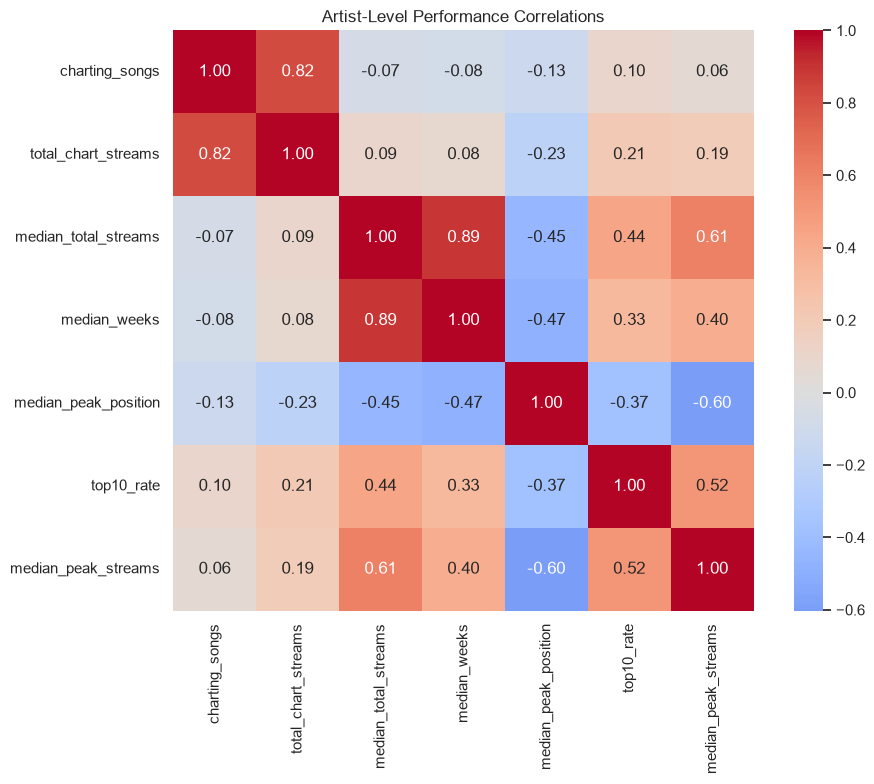

In [36]:
# Visualize

plt.figure(figsize=(10, 8))

sns.heatmap(
    artist_correlations,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title(
    "Artist-Level Performance Correlations"
)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "artist_performance_correlation.png",
    dpi=300,
    bbox_inches = "tight"
)

plt.show()
plt.close()

 30. Identify artists with multiple dimensions of strong performance
 Instead of a single ranking, filter for artists meeting several transparent criteria.

 For example.
 1) at least 5 charting songs,
 2) median chart longevity above the eligible-artist median
 3) median total streams above the eligible-artist median
 4) at least 2 Top-10 songs

In [37]:
# MULTI- DIMENSIONAL ARTIST PROFILE 

artist_multidimensional = eligible_artists[
    (eligible_artists["median_weeks"]
    >= eligible_artists["median_weeks"].median())
    &
    (eligible_artists["median_total_streams"]
    >= eligible_artists["median_total_streams"].median())
    &
    (eligible_artists["top10_songs"] >= 2)
].copy()

print(
    "Artists meeting all selected descriptive criteria:",
    len(artist_multidimensional)
)


display(
    artist_multidimensional[
        [
            "charting_songs",
            "median_weeks",
            "median_total_streams",
            "top10_songs",
            "top10_rate_pct"
        ]
    ]
    .sort_values(
        "median_total_streams",
        ascending=False
    )
    .head(25)
)

Artists meeting all selected descriptive criteria: 56


,charting_songs,median_weeks,median_total_streams,top10_songs,top10_rate_pct
artist name,,,,,
sombr,7,24.0,346775920.0,2,28.571429
Luis Fonsi,5,32.0,313526768.5,3,60.000000
Clean Bandit,9,32.0,280466909.0,3,33.333333
Charlie Puth,10,37.5,255482632.0,3,30.000000
Chappell Roan,8,15.0,192261802.5,2,25.000000
Rauw Alejandro,22,17.0,172667899.5,2,9.090909
Major Lazer,10,22.5,162001489.0,2,20.000000
Xavi,6,15.0,160061176.0,2,33.333333
LISA,7,10.0,157067632.0,2,28.571429


This is not an overall artist ranking. it is a transparent filter showing which artists meet the stated descriptive conditions.

In [38]:
# 31. Save artist-level master table - This is an important reusable output for later notebooks and your streamlit dashboard.

# SAVE ARTIST MASTER TABLE

ARTIST_TABLE_PATH = (
    TABLE_DIR /
    "artist_performance_master.csv"
)

artist_performance.to_csv(
    ARTIST_TABLE_PATH
)

print("Saved:")
print(ARTIST_TABLE_PATH)

Saved:
C:\Users\Sanu\OneDrive\Desktop\Spotify-Global-Hit-Intelligence\outputs\tables\artist_analytics\artist_performance_master.csv


In [39]:
# 32. Save other important tables

artist_profile_summary.to_csv(
    TABLE_DIR / "artist_profile_summary.csv"
)

artist_concentration.to_csv(
    TABLE_DIR / "artist_concentration.csv",
    index=False 
)

artist_peak_5plus.to_csv(
    TABLE_DIR / "artist_peak_performance.csv"
)

artist_longevity_5plus.to_csv(
    TABLE_DIR / "artist_longevity.csv"
)

artist_long_running_5plus.to_csv(
    TABLE_DIR / "artist_multidimensional_profile.csv"
)

print("All artist analytics tables saved.")

All artist analytics tables saved.


In [40]:
# 33. Verify the saved master table

# VERIFY OUTPUT

verify_artist = pd.read_csv(
    ARTIST_TABLE_PATH
)

print(
    "Artist master table shape:",
    verify_artist.shape
)

print(
    "File exists:",
    ARTIST_TABLE_PATH.exists()
)

Artist master table shape: (1793, 19)
File exists: True


In [43]:
# 34. Final artist analytics summary

# ARTIST ANALYTICS SUMMARY 

artist_summary = pd.DataFrame({

    "Metric": [
        "Unique artists",
        "Artists with 5+ charting songs",
        "Maximum charting songs by one artist",
        "Median charting songs per artist",
        "Artists with 2+ Top-10 songs",
        "Artists with 5+ charting songs and Top-10 rate >= 50%",
        "Highest aggregate artist streams"
    ],

    "Value": [
        df["artist name"].nunique(),

        len(artists_5plus),

        artist_performance["charting_songs"].max(),

        artist_performance["charting_songs"].median(),

        len(
            artist_performance[
                artist_performance["top10_songs"] >= 2
            ]
        ),

        len(
            artists_5plus[
                artists_5plus["top10_rate"] >= 0.50
            ]
        ),

        artist_performance[
            "total_chart_streams"
        ].max()
    ]


})

display(artist_summary)

,Metric,Value
0,Unique artists,1.793000e+03
1,Artists with 5+ charting songs,3.160000e+02
2,Maximum charting songs by one artist,2.460000e+02
3,Median charting songs per artist,1.000000e+00
4,Artists with 2+ Top-10 songs,1.060000e+02
5,Artists with 5+ charting songs and Top-10 rate...,1.000000e+00
6,Highest aggregate artist streams,3.113439e+10


### Artist Analysis - Key Findings

1. Artist Chart Presence

The number of charting songs varies substantially across artists. A relatively small group of artists accounts for a large portion of 
the chart records.

2. Catalog Size and Aggregate Streams

Artists with more charting songs can accumulate large aggregate streaming totals simply becasue they have more songs represented in the dataset.

Therefore, aggregate artist streams should be interpreted alongside catalog size.

3. Typical Song Performance

Median song-level performance provides a useful complementary measure because it is less sensitive to individual blockbuster songs than the mean.

4. Top-10 Repeat Performance

Some artists have multiple Top-10 songs, demonstrating repeated high-level chart presence rather than a single succesful release.

5. Artist Longevity

Artists differ in the typical number of weeks their songs remain on the chart. Median longevity provides a useful measure of the typical chart persistance of an artist's catalog.

6. Artist Consistency 

The coefficient of variation provides a descriptive measure of how dispersed an artist's song-level streaming perrformance is.

A lower value indicates less relative dispersion; it does not independently indicate superior performance.

7. Artist Profiles

Artists can exhibit different combinations of catalog size and typical song performance. This suggests that artist success is multidimensional rather than adequately represented by one aggregate metric.

8. Concentration

Chart representation is concentrated among a subset of artists. The cumulative artist-concentration analysis quantifies this effect.

9. Next Stage

The next notebook moves from artist-level metadata and chart performance into lyrics and Natural Language Processing.

The next question include:

- What lyrical characteristics are common among successful songs?
- Which words and phrases are associated with different performance profiles?
- Are there differences in lyric length, vocabulary, sentiment or themes?
- Can lyrics provide additional information beyond chart-performance variables?

These questions will be explored in `06_Lyrics_NLP.ipynb

One important methodological point

For this notebook, keep aggregate streams and catalog size separate from typical song performance.

For example
Artist A
50 charting songs
Rs / streams aggregate = very high 

doesn't necessarily mean its typical song performs better than:

Artist B
5 charting songs
median streams per song = very high

That's why this notebook uses count, aggregate, mean, median, rate and longevity as separate dimensions rather than constructing an arbitrary overall artist score.

Next: 06_Lyrics_NLP.ipynb - this is where the project becomes substantially more interesting from a Data Science perspective: text cleaning, tokenization, stopwords, word frequency, TF-IDF, n-grams, sentiment, lexical diversity, lyric length, word clouds and NLP-vs-chart-performance analysis.